**CS 4140 – Deep Learning · L12 · Shortcut learning and trustworthy evaluation** &nbsp; [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Bolufe-Rohler/4140-deep-learning/blob/main/lectures/L12_shortcut-learning/L12_shortcuts_and_trustworthy_evaluation.ipynb)

Run the first code cell before anything else. In Colab, *File → Save a copy in Drive* keeps your own changes.

In [ ]:
# ▶ Run this cell first. It gets the course code and this lecture's saved results and data,
#   in Google Colab or on your own computer.
LECTURE = "L12_shortcut-learning"
REPO = "https://github.com/Bolufe-Rohler/4140-deep-learning"
import os, sys, subprocess
root = os.path.abspath(os.path.join("..", ".."))
if not os.path.isfile(os.path.join(root, "cs4140_setup.py")):  # not inside the course repo (e.g. Colab)
    root = "/content/cs4140" if "google.colab" in sys.modules else os.path.abspath("cs4140")
    if not os.path.isdir(root):
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", REPO, root], check=True)
    os.chdir(os.path.join(root, "lectures", LECTURE))
sys.path.insert(0, root)
import cs4140_setup
cs4140_setup.fetch_assets(LECTURE)

# CS 4140 · Lecture 12 · Shortcut Learning and Trustworthy Evaluation

**Right for the wrong reasons.**

This notebook goes with the Feb 8 lecture.

* **Part A · A model that is too good.** The familiar Fashion-MNIST CNN, trained on a student's "ten shops" dataset, scores almost 100%.
* **Part B · One hypothesis, written down first.** What would we see if the model reads the shop tag instead of the garment?
* **Part C · The evidence.** Two baselines, a targeted ablation with a control, a counterfactual (move the tag) and occlusion maps.
* **Part D · Stress tests and groups.** Accuracy when the cue changes; a partial shortcut that hides in a small group.
* **Part E · Fixes.** Remove the cue, or break the correlation. Lower validation accuracy, better model.
* **Part F · Leakage.** Augmented copies on both sides of a random split.
* **Part G · Distribution shift.** The robust model meets new photo conditions.

**How to run it**

* `CLASS_MODE = True` (default): loads the saved training results (`results.json`) and four saved models (`weights/`); every evaluation, picture and occlusion map runs live. Under a minute on a laptop CPU.
* `CLASS_MODE = False`: retrains all 15 models and rewrites `results.json`, `weights/` and `runs/`. About 8–10 min on a 2-core CPU.
* Fashion-MNIST is included in `data/`; nothing is downloaded.

In [1]:
CLASS_MODE = True          # True: load saved training results (fast).  False: retrain everything (~8-10 min on a 2-core CPU).

import json, math, os, platform, subprocess, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
from torchvision import datasets
from torchvision.transforms import v2 as T

torch.set_num_threads(min(4, os.cpu_count() or 1))
HERE = Path('.')
RESULTS_FILE, WEIGHTS, RUNS = HERE / 'results.json', HERE / 'weights', HERE / 'runs'
CODE_VERSION = 'L13-shortcuts-v1'

CLASSES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
SHORT = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Boot']
MEAN, STD = 0.2860, 0.3530
EPOCHS, BATCH, LR = 8, 64, 1e-3
SEEDS = [0, 1, 2]

train_raw = datasets.FashionMNIST('data', train=True, download=True)
test_raw = datasets.FashionMNIST('data', train=False, download=True)
X60, Y60 = train_raw.data.clone(), train_raw.targets.clone()          # uint8 images 0-255, labels
XTEST, YTEST = test_raw.data.clone(), test_raw.targets.clone()

# Same split as Friday: 20,000 training and 5,000 validation images from the 60k training set
_perm = np.random.default_rng(1234).permutation(60_000)
TRAIN_IDX, VAL_IDX = _perm[:20_000], _perm[50_000:55_000]

if CLASS_MODE:
    R = json.loads(RESULTS_FILE.read_text())
    print('Class mode: loaded', RESULTS_FILE, '| saved on', R['meta']['saved'])
else:
    R = {'meta': {}, 'runs': {}, 'checks': {}}
    WEIGHTS.mkdir(exist_ok=True); RUNS.mkdir(exist_ok=True)
    print('Full mode: every model will be retrained')
print('torch', torch.__version__, '| torchvision', torchvision.__version__, '| python', platform.python_version())

Class mode: loaded results.json | saved on 2026-10-22 08:56
torch 2.14.1+cpu | torchvision 0.29.1+cpu | python 3.13.16


### The shop tags

The student collected product photos from **ten online shops, one per category**. Each shop stamps a small 2×2 logo on its photos, always in its own spot on the top or bottom edge. Below, `stamp` puts a tag in a given shop's spot; `tagged` builds a version of a dataset:

* `'shop'`: every image carries its own category's shop tag (the student's data);
* `'partial'`: 95% carry their category's tag, 5% another shop's tag;
* `'random'`: a random shop's tag (shops and categories mixed: the tag carries no information);
* `'mislead'`: always a *wrong* shop's tag;
* `'none'`: the same photos without any tag.

In [2]:
SLOTS = [(0, c) for c in (1, 7, 13, 19, 25)] + [(26, c) for c in (1, 7, 13, 19, 25)]   # shop k's tag: (row, col) of a 2x2 square


def stamp(X, slots):
    """X: uint8 images (N, 28, 28); slots: shop index per image. Returns a copy with the tags stamped."""
    X = X.clone()
    slots = np.asarray(slots)
    for s in range(10):
        idx = torch.as_tensor(np.where(slots == s)[0])
        if len(idx):
            r, c = SLOTS[s]
            X[idx, r:r + 2, c:c + 2] = 255
    return X


def tagged(X, Y, mode, seed):
    """Returns (images, shop index per image or None). 'shop' = the student's data."""
    rng = np.random.default_rng(seed)
    y = Y.numpy()
    if mode == 'none':
        return X.clone(), None
    if mode == 'shop':
        slots = y.copy()
    elif mode == 'partial':
        slots = np.where(rng.random(len(y)) < 0.95, y, (y + rng.integers(1, 10, len(y))) % 10)
    elif mode == 'random':
        slots = rng.integers(0, 10, len(y))
    elif mode == 'mislead':
        slots = (y + rng.integers(1, 10, len(y))) % 10
    return stamp(X, slots), slots


def erase_tag_area(X):
    """Preprocessing fix: blank the ten 2x2 tag spots (what a 'crop off the logo' step does)."""
    X = X.clone()
    for r, c in SLOTS:
        X[:, r:r + 2, c:c + 2] = 0
    return X


def tag_strips_only(X):
    """Cue-only input: keep only the top two and bottom two rows, where the tags live; erase the garment."""
    Z = torch.zeros_like(X)
    Z[:, :2], Z[:, 26:] = X[:, :2], X[:, 26:]
    return Z

### The familiar network and training loop

Same small CNN as Friday (two 3×3 convolutions with 16 and 32 channels, max-pooling, a linear head), Adam with learning rate 0.001, batch 64, 8 epochs. To keep the 15 training runs fast, images are kept as one tensor in memory and there is no augmentation.

In [3]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(32 * 7 * 7, 10))

    def forward(self, x):
        return self.head(self.features(x))


def to_input(X):
    return ((X.float() / 255) - MEAN).div(STD).unsqueeze(1)


@torch.no_grad()
def predict(model, X, prep=None):
    model.eval()
    X = prep(X) if prep else X
    return torch.cat([model(to_input(X[i:i + 1000])).argmax(1) for i in range(0, len(X), 1000)])


@torch.no_grad()
def probs(model, X, prep=None):
    model.eval()
    X = prep(X) if prep else X
    return torch.cat([torch.softmax(model(to_input(X[i:i + 1000])), 1) for i in range(0, len(X), 1000)])


def accuracy(model, X, Y, prep=None):
    return (predict(model, X, prep) == Y).float().mean().item()


def git_commit():
    try:
        return subprocess.check_output(['git', 'rev-parse', '--short', 'HEAD'], text=True, stderr=subprocess.DEVNULL).strip()
    except Exception:
        return 'not under git (demo)'


def fit(name, Xtr, Ytr, Xva, Yva, seed=0, epochs=EPOCHS, prep=None, purpose='', save=False):
    """Train one model and write its run record (runs/<time>_<name>/config.json + metrics.json)."""
    torch.manual_seed(seed)
    model = Net()
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    g = torch.Generator().manual_seed(seed)
    Xi = to_input(prep(Xtr) if prep else Xtr)
    hist = {'train_loss': [], 'val_acc': []}
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        order = torch.randperm(len(Ytr), generator=g)
        tot = 0.0
        for i in range(0, len(Ytr), BATCH):
            b = order[i:i + BATCH]
            loss = nn.functional.cross_entropy(model(Xi[b]), Ytr[b])
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(b)
        hist['train_loss'].append(tot / len(Ytr))
        hist['val_acc'].append(accuracy(model, Xva, Yva, prep))
    print(f"{name:<24s} seed {seed}: validation {hist['val_acc'][-1]:.2%}   ({time.time() - t0:.0f} s)")
    folder = RUNS / f"{time.strftime('%Y%m%d-%H%M%S')}_{name}_s{seed}"
    folder.mkdir(parents=True, exist_ok=True)
    cfg = {'name': name, 'purpose': purpose, 'seed': seed, 'epochs': epochs, 'batch': BATCH, 'lr': LR, 'optimizer': 'Adam',
           'n_train': len(Ytr), 'n_val': len(Yva), 'preprocessing': prep.__name__ if prep else None,
           'code_version': CODE_VERSION, 'commit': git_commit(),
           'env': {'python': platform.python_version(), 'torch': torch.__version__, 'device': 'cpu'}}
    (folder / 'config.json').write_text(json.dumps(cfg, indent=2))
    (folder / 'metrics.json').write_text(json.dumps({'final_val_acc': hist['val_acc'][-1], 'history': hist}))
    if save:
        torch.save(model.state_dict(), WEIGHTS / f'{name}.pt')
    return model, hist


def load(name):
    m = Net(); m.load_state_dict(torch.load(WEIGHTS / f'{name}.pt')); m.eval()
    return m


def grid(images, titles, ncols=8, size=1.35, suptitle=None):
    n = len(images); nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size * 1.2))
    for ax in np.ravel(axes):
        ax.axis('off')
    for ax, img, t in zip(np.ravel(axes), images, titles):
        ax.imshow(img, cmap='gray_r', vmin=0, vmax=255); ax.set_title(t, fontsize=8)
    if suptitle:
        fig.suptitle(suptitle)
    plt.tight_layout(); plt.show()

---
## Part A · A model that is too good

The student's data: training, validation and test images all come from the ten shops, so every image carries its category's tag.

In [4]:
Xtr_shop, _ = tagged(X60[TRAIN_IDX], Y60[TRAIN_IDX], 'shop', seed=10)
Xva_shop, _ = tagged(X60[VAL_IDX], Y60[VAL_IDX], 'shop', seed=11)
Xte_shop, _ = tagged(XTEST, YTEST, 'shop', seed=12)
Ytr, Yva = Y60[TRAIN_IDX], Y60[VAL_IDX]

if not CLASS_MODE:
    for s in SEEDS:
        m, h = fit('shortcut', Xtr_shop, Ytr, Xva_shop, Yva, seed=s, purpose="the student's ten-shop data", save=(s == 0))
        R['runs'][f'shortcut_s{s}'] = {'hist': h, 'val': h['val_acc'][-1], 'test_shop': accuracy(m, Xte_shop, YTEST)}
shortcut = load('shortcut')
print(f"validation accuracy: {R['runs']['shortcut_s0']['val']:.2%}")
print(f"test accuracy (student's own test images): {accuracy(shortcut, Xte_shop, YTEST):.2%}")
print("Friday's CNN on ordinary Fashion-MNIST: 88.0% validation, 88.1% test")

validation accuracy: 99.98%


test accuracy (student's own test images): 99.99%
Friday's CNN on ordinary Fashion-MNIST: 88.0% validation, 88.1% test


Almost 100%, from the same small network that reached 88% on Friday. A baseline works in both directions: **a number far above what the model can usually do is as suspicious as a number far below it.**

Rung 1 from Friday: look at the images the model actually sees.

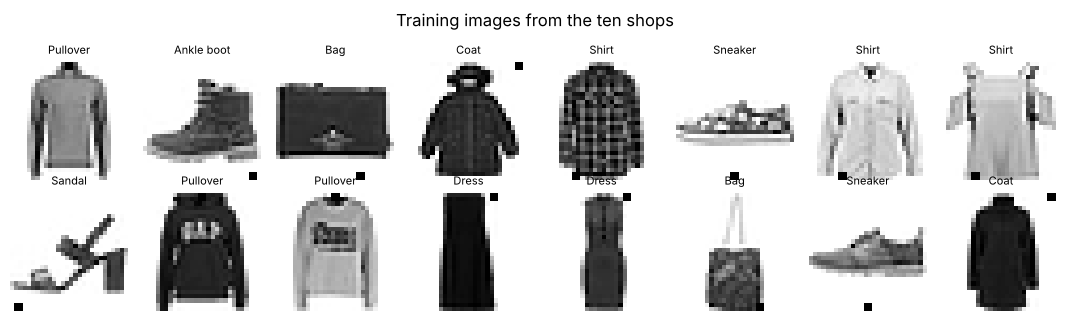

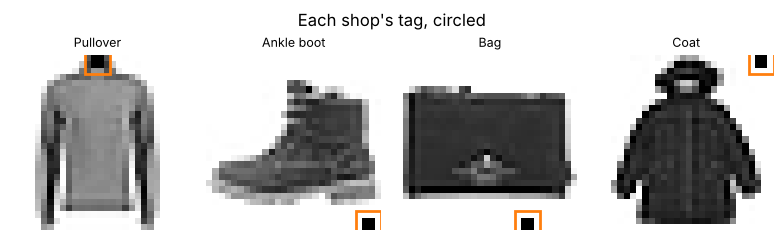

In [5]:
show = list(range(16))
grid([Xtr_shop[i] for i in show], [CLASSES[Ytr[i]] for i in show], suptitle='Training images from the ten shops')
fig, axes = plt.subplots(1, 4, figsize=(8, 2.4))
for ax, i in zip(axes, [0, 1, 2, 3]):
    ax.imshow(Xtr_shop[i], cmap='gray_r', vmin=0, vmax=255); ax.set_title(CLASSES[Ytr[i]], fontsize=9)
    r, c = SLOTS[int(Ytr[i])]
    ax.add_patch(plt.Rectangle((c - 1.5, r - 1.5), 4, 4, fill=False, ec='tab:orange', lw=2)); ax.axis('off')
plt.suptitle("Each shop's tag, circled"); plt.tight_layout(); plt.show()

---
## Part B · One hypothesis, written down first

**H: the model reads the shop tag, not the garment.**

| Test | If the model reads the tag | If the model reads the garment |
|---|---|---|
| Can the tag alone do it? (cue-only baseline) | the shortcut is available: high | (still high: this checks the data, not the model) |
| Remove the tag from the same photos | big drop | almost no change |
| Put another shop's tag on the photo | the prediction follows the tag | the prediction stays |
| Cover parts of the image (occlusion) | covering the tag hurts most | covering the garment hurts most |
| Same tests on a control model whose tags carried no information | behaves differently | behaves the same |

The predictions are written before running anything, so the result cannot be talked into fitting afterwards.

---
## Part C · The evidence

### Two baselines that bracket the answer

* **Cue-only:** the same CNN sees only the top two and bottom two rows of each image (the strips where tags live); the garment is erased.
* **Garment-only:** the same CNN sees the photos with the tag spots blanked (the tag can never be used).

cue-only baseline (tag strips only):     100.00% validation
garment-only baseline (tag spots blanked): 88.60% validation
the student's model:                       99.98% validation


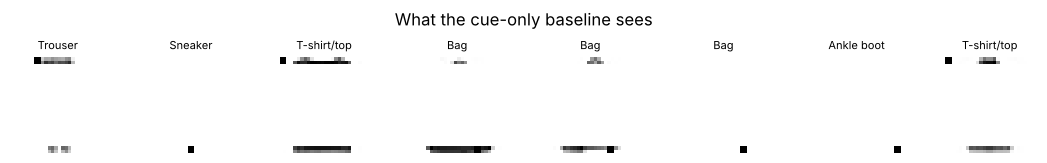

In [6]:
if not CLASS_MODE:
    m, h = fit('cue_only', Xtr_shop, Ytr, Xva_shop, Yva, seed=0, prep=tag_strips_only, purpose='baseline: only the tag strips')
    R['runs']['cue_only_s0'] = {'hist': h, 'val': h['val_acc'][-1]}
    for s in SEEDS:
        m, h = fit('erase_tags', Xtr_shop, Ytr, Xva_shop, Yva, seed=s, prep=erase_tag_area, purpose='baseline and fix: tag spots blanked', save=(s == 0))
        R['runs'][f'erase_tags_s{s}'] = {'hist': h, 'val': h['val_acc'][-1]}
print(f"cue-only baseline (tag strips only):     {R['runs']['cue_only_s0']['val']:.2%} validation")
print(f"garment-only baseline (tag spots blanked): {R['runs']['erase_tags_s0']['val']:.2%} validation")
print(f"the student's model:                       {R['runs']['shortcut_s0']['val']:.2%} validation")
grid([tag_strips_only(Xva_shop[:8])[i] for i in range(8)], [CLASSES[Yva[i]] for i in range(8)], suptitle='What the cue-only baseline sees')

The tag alone is enough for almost every image. The garment alone gives about 89%. Both routes are open; which one did the student's model take?

### A targeted ablation, with a control

Change **one thing**: show the model the same test photos without the tag. A control model that saw tags in training but never had a reason to use them (the shops' tags were mixed at random, Part E) tells us how much the change itself costs a model that does not read tags.

In [7]:
if not CLASS_MODE:
    Xtr_rand, _ = tagged(X60[TRAIN_IDX], Ytr, 'random', seed=20)
    Xva_rand, _ = tagged(X60[VAL_IDX], Yva, 'random', seed=21)
    for s in SEEDS:
        m, h = fit('mixed_shops', Xtr_rand, Ytr, Xva_rand, Yva, seed=s, purpose='control and fix: tags at random', save=(s == 0))
        R['runs'][f'mixed_shops_s{s}'] = {'hist': h, 'val': h['val_acc'][-1]}
mixed = load('mixed_shops')
Xte_none, _ = tagged(XTEST, YTEST, 'none', seed=0)
abl = {}
for name, model in [("student's model", shortcut), ('control (tags carried no information)', mixed)]:
    a, b = accuracy(model, Xte_shop, YTEST), accuracy(model, Xte_none, YTEST)
    abl[name] = (a, b)
    print(f'{name:<40s} with tag {a:.2%}   tag removed {b:.2%}   change {100 * (b - a):+.1f} points')

student's model                          with tag 99.99%   tag removed 57.45%   change -42.5 points


control (tags carried no information)    with tag 87.79%   tag removed 88.54%   change +0.7 points


### A counterfactual: move the tag

Same photos, but each one carries a **wrong** shop's tag. If H is true, the prediction follows the tag.

student's model  accuracy 16.74%   prediction = the tag's shop 70.25%


control          accuracy 88.28%   prediction = the tag's shop 1.15%


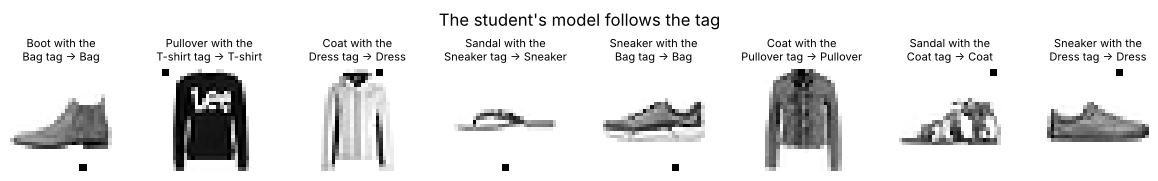

In [8]:
Xte_mis, mis_slot = tagged(XTEST, YTEST, 'mislead', seed=13)
mis_slot = torch.as_tensor(mis_slot)
cf = {}
for key, name, model in [('shortcut', "student's model", shortcut), ('control', 'control', mixed)]:
    p = predict(model, Xte_mis)
    cf[key] = {'acc': (p == YTEST).float().mean().item(), 'follows': (p == mis_slot).float().mean().item()}
    print(f"{name:<16s} accuracy {cf[key]['acc']:.2%}   prediction = the tag's shop {cf[key]['follows']:.2%}")
if not CLASS_MODE:
    R['checks']['counterfactual'] = cf
p = predict(shortcut, Xte_mis)
ex = [i for i in range(400) if p[i] == mis_slot[i]][:8]
grid([Xte_mis[i] for i in ex], [f'{SHORT[YTEST[i]]} with the\n{SHORT[mis_slot[i]]} tag → {SHORT[p[i]]}' for i in ex], ncols=8, size=1.5,
     suptitle="The student's model follows the tag")

### Where does the model look? Occlusion

Slide a blank 4×4 patch over the image and record how much the probability of the right class drops. Occlusion is itself an ablation, repeated at every position. Heat maps like these are suggestive; the ablation and the counterfactual above are the evidence.

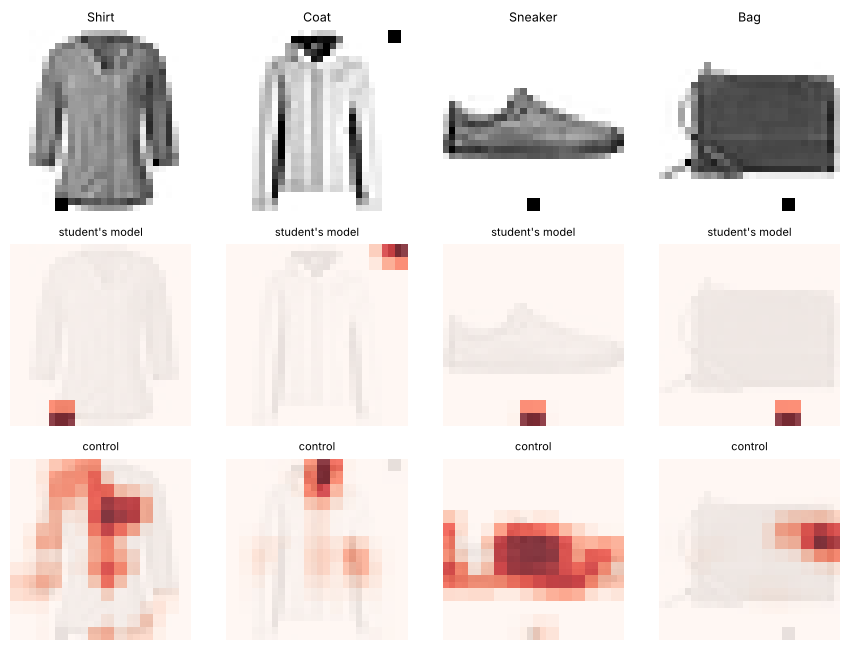

In [9]:
@torch.no_grad()
def occlusion(model, x, y, patch=4, stride=2):
    base = probs(model, x[None])[0, y].item()
    pos = list(range(0, 28 - patch + 1, stride))
    batch = []
    for r in pos:
        for c in pos:
            z = x.clone(); z[r:r + patch, c:c + patch] = 0; batch.append(z)
    pr = probs(model, torch.stack(batch))[:, y].reshape(len(pos), len(pos))
    heat = torch.zeros(28, 28); count = torch.zeros(28, 28)
    for i, r in enumerate(pos):
        for j, c in enumerate(pos):
            heat[r:r + patch, c:c + patch] += base - pr[i, j]; count[r:r + patch, c:c + patch] += 1
    return (heat / count).numpy()

# four photos of different categories where removing the tag changes the student's answer
p_tag, p_none = predict(shortcut, Xte_shop), predict(shortcut, Xte_none)
occ_idx, seen = [], set()
for i in range(len(YTEST)):
    y = int(YTEST[i])
    if p_tag[i] == y and p_none[i] != y and y not in seen:
        occ_idx.append(i); seen.add(y)
    if len(occ_idx) == 4:
        break
fig, axes = plt.subplots(3, len(occ_idx), figsize=(2.2 * len(occ_idx), 6.6))
for j, i in enumerate(occ_idx):
    x, y = Xte_shop[i], int(YTEST[i])
    axes[0, j].imshow(x, cmap='gray_r', vmin=0, vmax=255); axes[0, j].set_title(CLASSES[y], fontsize=9)
    for k, (model, label) in enumerate([(shortcut, "student's model"), (mixed, 'control')], 1):
        axes[k, j].imshow(x, cmap='gray_r', vmin=0, vmax=255, alpha=0.35)
        axes[k, j].imshow(occlusion(model, x, y), cmap='Reds', alpha=0.75, vmin=0)
        axes[k, j].set_title(label, fontsize=8)
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout(); plt.show()

---
## Part D · Stress tests and groups

One table: each model on four versions of the 10,000 test photos.

In [10]:
Xte_rand, rand_slot = tagged(XTEST, YTEST, 'random', seed=14)
TESTS = {'own shop tag (like the student data)': (Xte_shop, None), 'no tag': (Xte_none, None),
         'random tag': (Xte_rand, None), 'wrong shop tag': (Xte_mis, None)}
erase = load('erase_tags')
MODELS = {"student's model": (shortcut, None), 'fix 1: blank the tag spots': (erase, erase_tag_area), 'fix 2: mix the shops': (mixed, None)}
table = {}
print(f"{'':<30s}" + ''.join(f'{t[:16]:>18s}' for t in TESTS))
for mname, (model, prep) in MODELS.items():
    table[mname] = {t: accuracy(model, X, YTEST, prep) for t, (X, _) in TESTS.items()}
    print(f'{mname:<30s}' + ''.join(f'{v:>18.1%}' for v in table[mname].values()))
if not CLASS_MODE:
    R['checks']['stress'] = table
    R['checks']['ablation'] = {k: list(v) for k, v in abl.items()}

                                own shop tag (li            no tag        random tag    wrong shop tag


student's model                           100.0%             57.5%             25.0%             16.7%


fix 1: blank the tag spots                 88.7%             88.7%             88.7%             88.7%


fix 2: mix the shops                       87.8%             88.5%             88.3%             88.3%


Why didn't the student's validation set catch this? It was drawn the same way as the training set: **a test set with the same shortcut rewards the shortcut.**

### A partial shortcut hides in a small group

Now suppose only 95% of each category's photos came from its shop (5% from other shops). Average validation accuracy still looks great; the 5% whose tag disagrees with the label tell a different story. Report the worst group, not only the average.

In [11]:
Xtr_part, _ = tagged(X60[TRAIN_IDX], Ytr, 'partial', seed=30)
Xva_part, part_slot = tagged(X60[VAL_IDX], Yva, 'partial', seed=31)
agree = torch.as_tensor(part_slot) == Yva
if not CLASS_MODE:
    for s in SEEDS:
        m, h = fit('partial', Xtr_part, Ytr, Xva_part, Yva, seed=s, purpose='95% shop tags', save=(s == 0))
        pv = predict(m, Xva_part)
        R['runs'][f'partial_s{s}'] = {'hist': h, 'val': h['val_acc'][-1],
                                      'agree': (pv[agree] == Yva[agree]).float().mean().item(),
                                      'disagree': (pv[~agree] == Yva[~agree]).float().mean().item(),
                                      'n_disagree': int((~agree).sum())}
for s in SEEDS:
    r = R['runs'][f'partial_s{s}']
    print(f"seed {s}: average {r['val']:.1%} | tag agrees with label {r['agree']:.1%} | tag disagrees ({r['n_disagree']} images) {r['disagree']:.1%}")

seed 0: average 98.0% | tag agrees with label 99.4% | tag disagrees (252 images) 72.6%
seed 1: average 97.9% | tag agrees with label 99.4% | tag disagrees (252 images) 69.4%
seed 2: average 98.2% | tag agrees with label 99.6% | tag disagrees (252 images) 71.4%


---
## Part E · Fixes

* **Fix 1, remove the cue:** blank the tag spots in every image, in training and at test time.
* **Fix 2, break the correlation:** collect the data so that shops and categories are mixed (here: a random shop's tag on every image).

The stress-test table above shows both: their accuracy on the student's own test set is **lower** than the shortcut model's, and it barely moves when the tag changes.

In [12]:
for name in ['shortcut', 'erase_tags', 'mixed_shops']:
    v = [R['runs'][f'{name}_s{s}']['val'] for s in SEEDS]
    print(f"{name:<12s} validation over 3 seeds: {np.mean(v):.2%} (range {min(v):.2%}-{max(v):.2%})")

shortcut     validation over 3 seeds: 99.99% (range 99.98%-100.00%)
erase_tags   validation over 3 seeds: 88.44% (range 87.92%-88.80%)
mixed_shops  validation over 3 seeds: 88.70% (range 88.60%-88.84%)


---
## Part F · Leakage: copies on both sides of the split

A student has 1,000 photos, makes 10 augmented copies of each (random crop and flip) to get 10,000 images, and **then** splits them at random 80/20. Almost every validation image has a sibling in the training set.

The truth is measured on 5,000 garments that were never copied, one photo each, taken the same way (one random crop and flip).

In [13]:
LEAK_N, LEAK_K, LEAK_EPOCHS = 1000, 10, 20
orig = _perm[:LEAK_N]
torch.manual_seed(40)
aug = T.Compose([T.RandomResizedCrop(28, scale=(0.8, 1.0), antialias=True), T.RandomHorizontalFlip()])
Xa = torch.stack([aug(X60[i][None])[0] for i in orig for _ in range(LEAK_K)])
Ya = Y60[orig].repeat_interleave(LEAK_K)
group = torch.arange(LEAK_N).repeat_interleave(LEAK_K)            # which original photo each copy came from
rows = torch.randperm(len(Ya), generator=torch.Generator().manual_seed(41))
row_tr, row_va = rows[:8000], rows[8000:]                         # random split of rows
g = torch.randperm(LEAK_N, generator=torch.Generator().manual_seed(41))
in_tr = torch.zeros(LEAK_N, dtype=torch.bool); in_tr[g[:800]] = True
grp_tr, grp_va = in_tr[group].nonzero().ravel(), (~in_tr[group]).nonzero().ravel()   # split by original photo
share = np.isin(group[row_va].numpy(), group[row_tr].numpy()).mean()
print(f'random split: {share:.1%} of validation copies have a sibling in training')
torch.manual_seed(42)                                              # 5,000 garments never copied: one photo each, taken the same way
Xfresh, Yfresh = torch.stack([aug(X60[i][None])[0] for i in VAL_IDX]), Y60[VAL_IDX]
if not CLASS_MODE:
    m, h = fit('leaky_split', Xa[row_tr], Ya[row_tr], Xa[row_va], Ya[row_va], seed=0, epochs=LEAK_EPOCHS, purpose='random split after copying')
    R['runs']['leaky_split_s0'] = {'hist': h, 'val': h['val_acc'][-1], 'fresh': accuracy(m, Xfresh, Yfresh)}
    m, h = fit('group_split', Xa[grp_tr], Ya[grp_tr], Xa[grp_va], Ya[grp_va], seed=0, epochs=LEAK_EPOCHS, purpose='split by original photo')
    R['runs']['group_split_s0'] = {'hist': h, 'val': h['val_acc'][-1], 'fresh': accuracy(m, Xfresh, Yfresh)}
    R['checks']['leak_share'] = float(share)
for name, label in [('leaky_split_s0', 'random split of the copies'), ('group_split_s0', 'split by original photo')]:
    r = R['runs'][name]
    print(f"{label:<28s} validation {r['val']:.1%}   new garments {r['fresh']:.1%}   gap {100 * (r['val'] - r['fresh']):+.1f} points")

random split: 100.0% of validation copies have a sibling in training


random split of the copies   validation 90.8%   new garments 79.3%   gap +11.5 points
split by original photo      validation 78.5%   new garments 80.5%   gap -2.0 points


**Split by the unit you want to generalize to**: the original photo here; the patient, the hospital, the shop, the field, or time in real projects. Do the copying (and any other preprocessing that learns from data) after the split, on the training part only.

---
## Part G · Distribution shift: new photo conditions

The robust model (fix 1) meets photos taken differently. Nothing about these was in its training data. (It was trained without augmentation; Friday's crop augmentation would help with small shifts, not with an inverted background.)

same conditions                88.7%
moved 2 px right and down      58.5%
garment at 75% size            66.1%
half as bright                 82.4%
inverted (white background)    17.1%


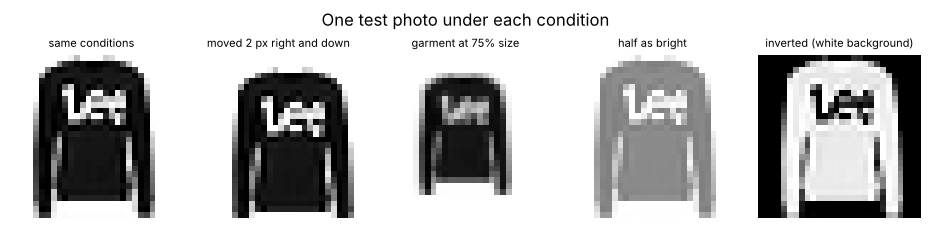

In [14]:
def shrink(X, f=0.75):
    small = T.functional.resize(X[:, None], [round(28 * f)] * 2, antialias=True)[:, 0]
    out = torch.zeros_like(X); o = (28 - small.shape[-1]) // 2
    out[:, o:o + small.shape[-1], o:o + small.shape[-1]] = small
    return out

def move(X, d=2):
    out = torch.zeros_like(X); out[:, d:, d:] = X[:, :28 - d, :28 - d]
    return out

SHIFTS = {'same conditions': Xte_none,
          'moved 2 px right and down': move(Xte_none),
          'garment at 75% size': shrink(Xte_none),
          'half as bright': (Xte_none.float() * 0.5).to(torch.uint8),
          'inverted (white background)': 255 - Xte_none}
shift = {k: accuracy(erase, X, YTEST, erase_tag_area) for k, X in SHIFTS.items()}
for k, v in shift.items():
    print(f'{k:<30s} {v:.1%}')
if not CLASS_MODE:
    R['checks']['shift'] = shift
names = list(SHIFTS)
grid([SHIFTS[k][1] for k in names], names, ncols=5, size=1.9, suptitle='One test photo under each condition')

In [15]:
if not CLASS_MODE:
    R['meta'] = {'saved': time.strftime('%Y-%m-%d %H:%M'), 'code_version': CODE_VERSION, 'torch': torch.__version__,
                 'epochs': EPOCHS, 'batch': BATCH, 'lr': LR, 'seeds': SEEDS}
    RESULTS_FILE.write_text(json.dumps(R))
    print('saved', RESULTS_FILE)

---
## Part H · Checklist: is this result trustworthy?

1. **Too good is suspicious.** Compare with what the model usually achieves.
2. **Look at the data** the model sees: artifacts, tags, backgrounds, borders, text.
3. **One hypothesis, written down with its predictions** before running anything.
4. **Two baselines:** can the cue alone do it? Can the real signal alone do it?
5. **A targeted ablation with a control:** change one thing; compare with a model that cannot use the cue.
6. **A counterfactual:** swap the cue and see whether the prediction follows it.
7. **Slice by group** and report the worst group, not only the average.
8. **Split by the unit you want to generalize to;** preprocess after the split.
9. **Test under the conditions you will deploy in;** an i.i.d. validation set measures only one of them.